# 5.35

| Row | $m_n$     |    $m_{n+1/2}$  | $m^*_{n+1/2}$     | $m_n$     | Order of Error | Name |
|-----|-----------|-----------------|-------------------|-----------|----------------|------|
| 1   | 1         | 0               | 0                 | 0         | $O(\Delta t)$  | Euler's Method |
| 2   | 0         | 1               | 0                 | 0         | $O(\Delta t^2)$ | Midpoint Method |
| 3   | 1/2       | 1/2             | 0                 | 0         | $O(\Delta t^2)$ | --- |
| 4   | 1/3       | 1/3             | 0                 | 1/3       | $O(\Delta t^3)$ | --- |
| 5   | 1/4       | 2/4             | 0                 | 1/4       | $O(\Delta t^3)$ | --- |
| 6   | 0         | 0               | 1                 | 0         | $O(\Delta t^3)$ | --- |
| 7   | 0         | 1/2             | 1/2               | 0         | $O(\Delta t^2)$ | --- |
| 8   | 1/3       | 1/3             | 1/3               | 0         | $O(\Delta t^3)$ | --- |
| 9   | 1/4       | 1/4             | 1/4               | 1/4       | $O(\Delta t^4)$ | RK4 |
| 10  | 1/5       | 2/5             | 1/5               | 1/5       | $O(\Delta t^4)$ | --- |
| 11  | 1/5       | 1/5             | 2/5               | 1/5       | $O(\Delta t^4)$ | --- |
| 12  | 1/6       | 2/6             | 2/6               | 1/6       | $O(\Delta t^4)$ | --- |
| 13  | 1/6       | 3/6             | 1/6               | 1/6       | $O(\Delta t^4)$ | --- |
| 14  | 1/6       | 1/6             | 3/6               | 1/6       | $O(\Delta t^4)$ | --- |
| 15  | 1/7       | 2/7             | 3/7               | 1/7       | $O(\Delta t^4)$ | --- |
| 16  | 1/8       | 3/8             | 3/8               | 1/8       | $O(\Delta t^4)$ | --- |
| 17  | | | | | | |
| 18  | | | | | | |

# 5.38

The given scenario aims to solve the differential equation $x' = f(t, x)$ on the interval $t\in [0, 1]$, width of the interval is $1-0 = 1$ such that the absolute error is less than $10^{-8}$. The step size is $\Delta t$ and the number of function evaluations are estimated for different methods.

## a) Euler's Method
Order of Error: $O(\Delta t)$<br>
Step Size: $\Delta t$ is estimated as $\Delta t \approx e$ where $e$ is the error $< 10^{-8}$<br>
Function Evaluation: $\frac{1}{\Delta t}$

## b) the midpoint method
Order of Error: $O((\Delta t)^2)$<br>
Step Size: $\Delta t \approx \sqrt{e}$ <br>
Function Evaluation: $2\times \frac{1}{\Delta t}$

## c) RK4 method
Order of Error: $O((\Delta t)^4)$<br>
Step Size: $\Delta t \approx \sqrt[4]{e}$ <br>
Function Evaluation: $4 \times \frac{1}{\Delta t}$


## d) Implications
Higher-oder method seems have less step size and achieve higher accuracy, and it needs to apply less function evaluations.


# 5.39

I think that the process will not change compared to the previous exercise, except the error will be less than $10^{-15}$ and then make the step size and their number of function evaluations be smaller.

# 5.41

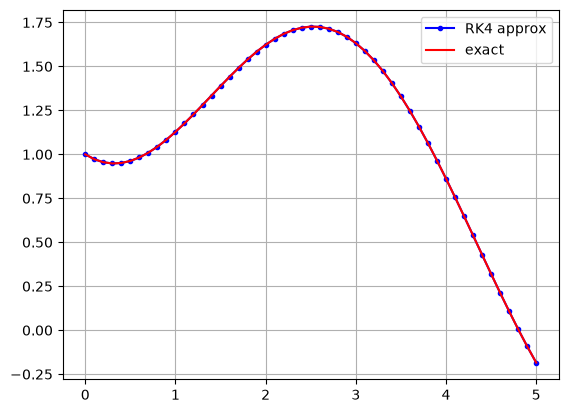

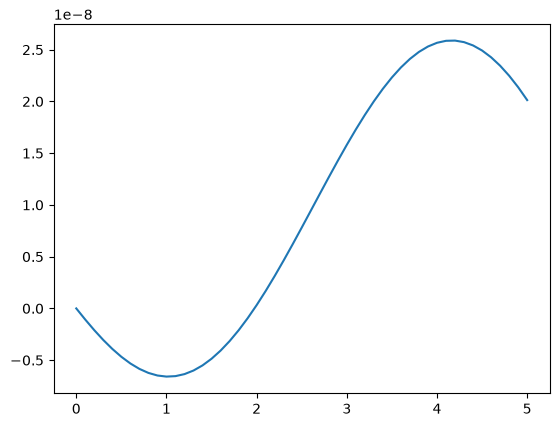

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def rk41d(f,x0,t0,tmax,dt):
    t = np.arange(t0,tmax+dt,dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t)-1):
        # the interesting bits of the code go here
        k1 = f(t[n], x[n])
        k2 = f(t[n] + dt/2, x[n] + dt/2 * k1)
        k3 = f(t[n] + dt/2, x[n] + dt/2 * k2)
        k4 = f(t[n] + dt, x[n] + dt * k3)
        x[n+1] = x[n] + dt/6 * (k1 + 2*k2 + 2*k3 + k4)
    return t, x

f = lambda t, x: -(1/3.0)*x + np.sin(t)
exact = lambda t: (1/10.0)*(19*np.exp(-t/3) + 3*np.sin(t) - 9*np.cos(t))

x0 = 1# initial condition
t0 = 0
tmax = 5 # your choice
dt = 0.1 # pick something reasonable
t_val = np.arange(t0, tmax+dt,dt)
t, x = rk41d(f,x0,t0,tmax,dt)
plt.plot(t,x,'b.-')
plt.plot(t_val, exact(t_val), 'r-')
plt.legend(['RK4 approx', 'exact'])
plt.grid()

plt.figure()
plt.plot(t, x - exact(t))
plt.show()

In [2]:
def euler(f, x0, t0, tmax, dt):
    """Explicit Euler method for a scalar IVP."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        x[n + 1] = x[n] + dt * f(t[n], x[n])
    return t, x


def midpoint(f, x0, t0, tmax, dt):
    """Midpoint (second-order Runge-Kutta) method."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        half_step = x[n] + 0.5 * dt * f(t[n], x[n])
        x[n + 1] = x[n] + dt * f(t[n] + 0.5 * dt, half_step)
    return t, x


def rk41d(f, x0, t0, tmax, dt):
    """Classical fourth-order Runge-Kutta method."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        k1 = f(t[n], x[n])
        k2 = f(t[n] + dt / 2, x[n] + dt * k1 / 2)
        k3 = f(t[n] + dt / 2, x[n] + dt * k2 / 2)
        k4 = f(t[n] + dt, x[n] + dt * k3)
        x[n + 1] = x[n] + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return t, x


def ode_test(f, x0, t0, tmax, dt, coeffs):
    """General four-stage Runge-Kutta method with weights `coeffs`."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        k1 = f(t[n], x[n])
        k2 = f(t[n] + dt / 2, x[n] + dt * k1 / 2)
        k3 = f(t[n] + dt / 2, x[n] + dt * k2 / 2)
        k4 = f(t[n] + dt, x[n] + dt * k3)
        x[n + 1] = x[n] + dt * np.dot(coeffs, (k1, k2, k3, k4))
    return t, x


euler     max error: [np.float64(0.034840046243517886), np.float64(0.0033870075388993115), np.float64(0.00033774211685377864)]
midpoint  max error: [np.float64(0.0007133724322669899), np.float64(6.89097886841239e-06), np.float64(6.86656784765205e-08)]
rk4       max error: [np.float64(1.5804531017238332e-08), np.float64(1.5361045768713666e-12), np.float64(3.552713678800501e-15)]
custom    max error: [np.float64(1.5804531017238332e-08), np.float64(1.5361045768713666e-12), np.float64(3.3306690738754696e-15)]


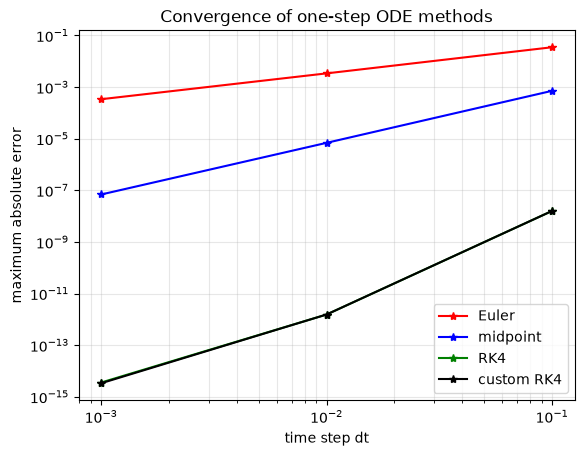

In [3]:
f = lambda t, x: -(1 / 3.0) * x + np.sin(t)
exact = lambda t: (1 / 10.0) * (19 * np.exp(-t / 3) + 3 * np.sin(t) - 9 * np.cos(t))

coeffs = np.array([1 / 6, 1 / 3, 1 / 3, 1 / 6])

x0 = 1
t0 = 0
tmax = 3
H = 10.0 ** (-np.arange(1, 4))

errors = {"euler": [], "midpoint": [], "rk4": [], "custom": []}
for dt in H:
    t, x_euler = euler(f, x0, t0, tmax, dt)
    t, x_midpoint = midpoint(f, x0, t0, tmax, dt)
    t, x_rk4 = rk41d(f, x0, t0, tmax, dt)
    t, x_custom = ode_test(f, x0, t0, tmax, dt, coeffs)
    reference = exact(t)
    errors["euler"].append(np.max(np.abs(x_euler - reference)))
    errors["midpoint"].append(np.max(np.abs(x_midpoint - reference)))
    errors["rk4"].append(np.max(np.abs(x_rk4 - reference)))
    errors["custom"].append(np.max(np.abs(x_custom - reference)))

for name, values in errors.items():
    print(f"{name:9s} max error: {values}")

plt.loglog(H, errors["euler"], "r*-", label="Euler")
plt.loglog(H, errors["midpoint"], "b*-", label="midpoint")
plt.loglog(H, errors["rk4"], "g*-", label="RK4")
plt.loglog(H, errors["custom"], "k*-", label="custom RK4")
plt.xlabel("time step dt")
plt.ylabel("maximum absolute error")
plt.title("Convergence of one-step ODE methods")
plt.grid(which="both", alpha=0.3)
plt.legend()
plt.show()
